In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

In [16]:
data = load_iris()
df = pd.DataFrame(data.data, columns=data.feature_names)
features = df[['sepal length (cm)', 'sepal width (cm)']]

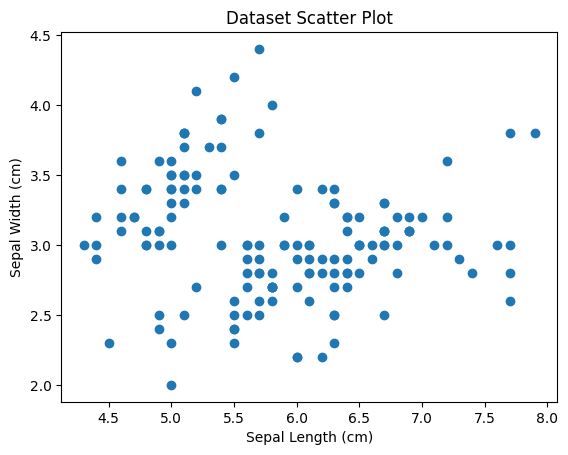

In [17]:
plt.scatter (features['sepal length (cm)'], features ['sepal width (cm)'])
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Dataset Scatter Plot')
plt.show()

In [21]:
kmeans = KMeans (n_clusters=3, random_state=42)
kmeans.fit(features)

KMeans(n_clusters=3, random_state=42)

In [23]:
labels = kmeans.labels_
print(labels)

[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 1 0 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1
 0 0 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 0 1 0 0 0 0
 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 0 1 0
 0 1]


In [24]:
df['cluster'] = labels
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   cluster  
0        2  
1        2  
2        2  
3        2  
4        2  


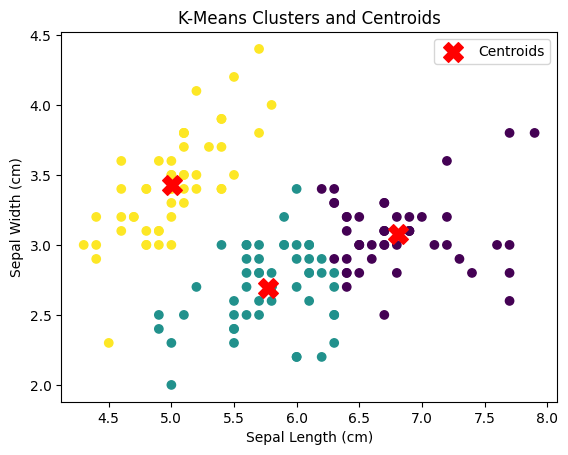

In [28]:
plt.scatter(features['sepal length (cm)'], features['sepal width (cm)'], c = labels , cmap = 'viridis')
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], marker='X', s = 200, c='red', label='Centroids')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('K-Means Clusters and Centroids')
plt.legend()
plt.show()

In [31]:
wcss = []
for i in range(1, 11):
  kmeans = KMeans (n_clusters=i, random_state=42)
  kmeans.fit(features)
  wcss.append(kmeans.inertia_)
print(wcss)

[130.4752666666667, 58.44759246088194, 37.0507021276596, 28.41365317351379, 26.9325075582776, 17.463509575220108, 14.828543464836567, 12.843135057471263, 12.530893304970899, 9.854376984126986]


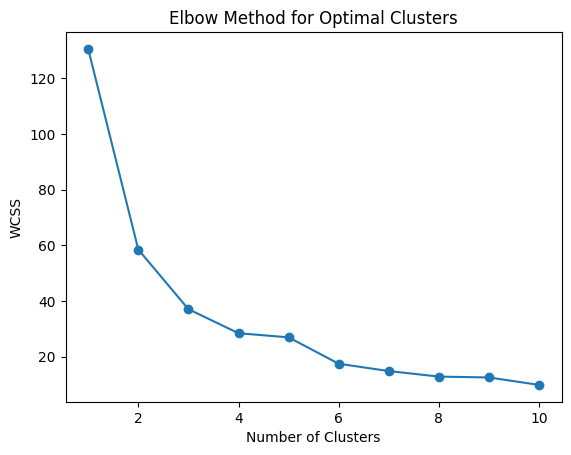

In [32]:
plt.plot(range (1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal Clusters')
plt.show()
# Inspect the plot; the elbow is often at 3 for this dataset.

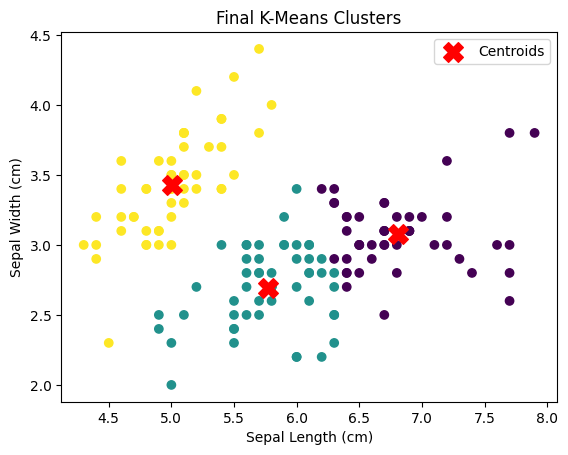

In [34]:
optimal_k = 3 # Adjust based on elbow plot
kmeans_optimal = KMeans (n_clusters = optimal_k, random_state = 42 )
kmeans_optimal.fit (features)
labels_optimal = kmeans_optimal.labels_
df['optimal_cluster'] = labels_optimal

plt.scatter (features['sepal length (cm)'], features['sepal width (cm)'], c = labels_optimal, cmap='viridis')
centroids_optimal = kmeans_optimal.cluster_centers_
plt.scatter (centroids_optimal [:, 0], centroids_optimal[:, 1], marker='X', s = 200, c='red', label='Centroids')
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title('Final K-Means Clusters')
plt.legend()
plt.show()

In [35]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

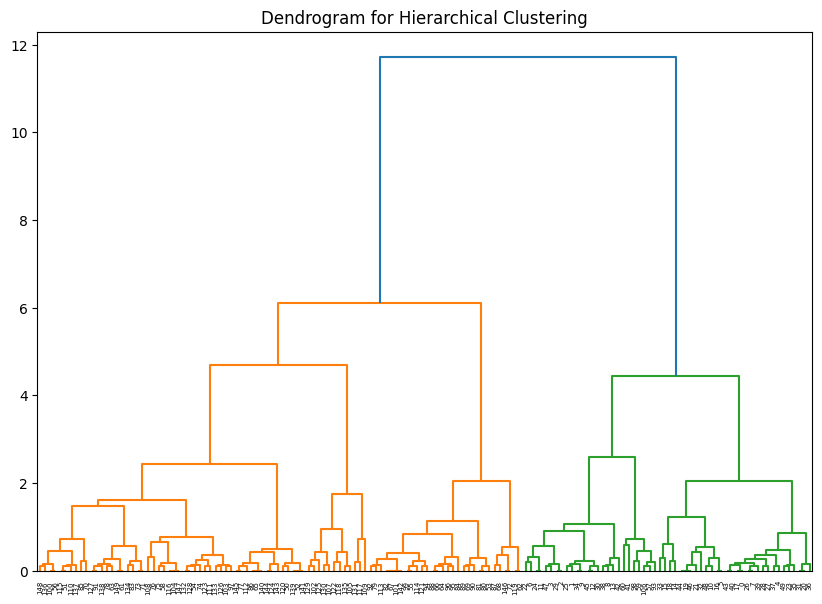

In [38]:
linked = linkage(features, method = 'ward')
plt.figure(figsize=(10, 7))
dendrogram (linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.title('Dendrogram for Hierarchical Clustering')
plt.show()
#Use the dendrogram to estimate the number of clusters
#(e.g., cut at a suitable height: suggesting 3 clusters).

In [40]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc.fit(features)

AgglomerativeClustering(n_clusters=3)

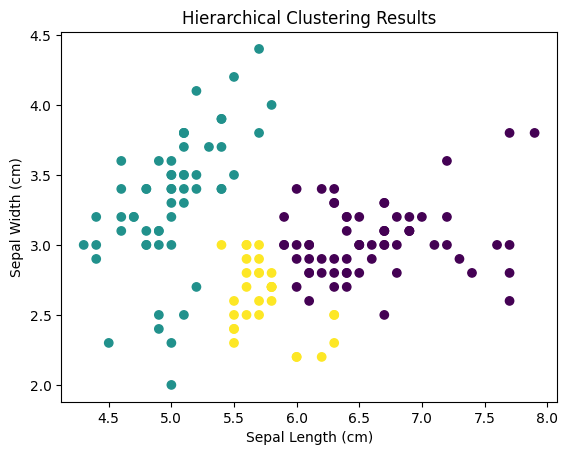

In [42]:
hc_labels = hc.labels_
plt.scatter(features['sepal length (cm)'], features ['sepal width (cm)'], c=hc_labels, cmap='viridis')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Hierarchical Clustering Results')
plt.show()